# Recurrent Neural Network

# Part 1 - Data Preprocessing

In [7]:
# Importing the libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [9]:
# Importing the training set
dataset_train = pd.read_csv('c:/Data/Google_Stock_Price_Train.csv')
training_set = dataset_train.iloc[:, 1:2].values

In [11]:
# Feature Scaling
from sklearn.preprocessing import MinMaxScaler
sc = MinMaxScaler(feature_range = (0, 1))
training_set_scaled = sc.fit_transform(training_set)

In [13]:
# Creating a data structure with 60 timesteps and 1 output
X_train = []
y_train = []
for i in range(60, 1258):
    X_train.append(training_set_scaled[i-60:i, 0])
    y_train.append(training_set_scaled[i, 0])
X_train, y_train = np.array(X_train), np.array(y_train)

In [15]:
# Reshaping
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))

# Part 2 - Building the RNN

In [19]:
# Importing the Keras libraries and packages
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from keras.layers import Dropout

In [21]:
# Initialising the RNN
regressor = Sequential()

In [23]:
# Adding the first LSTM layer and some Dropout regularisation
regressor.add(LSTM(units = 50, return_sequences = True, input_shape = (X_train.shape[1], 1)))
regressor.add(Dropout(0.2))

# Adding a second LSTM layer and some Dropout regularisation
regressor.add(LSTM(units = 50, return_sequences = True))
regressor.add(Dropout(0.2))

# Adding a third LSTM layer and some Dropout regularisation
regressor.add(LSTM(units = 50, return_sequences = True))
regressor.add(Dropout(0.2))

# Adding a fourth LSTM layer and some Dropout regularisation
regressor.add(LSTM(units = 50))
regressor.add(Dropout(0.2))

# Adding the output layer
regressor.add(Dense(units = 1))

C:\Users\akhil\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [25]:
# Compiling the RNN
regressor.compile(optimizer = 'adam', loss = 'mean_squared_error')

In [35]:
# Fitting the RNN to the Training set
regressor.fit(X_train, y_train, epochs = 200, batch_size = 42)

Epoch 1/200
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 167ms/step - loss: 0.0016
Epoch 2/200
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 167ms/step - loss: 0.0016
Epoch 3/200
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 164ms/step - loss: 0.0016
Epoch 4/200
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 164ms/step - loss: 0.0012
Epoch 5/200
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 162ms/step - loss: 0.0015
Epoch 6/200
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 165ms/step - loss: 0.0013
Epoch 7/200
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 173ms/step - loss: 0.0013
Epoch 8/200
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 174ms/step - loss: 0.0014
Epoch 9/200
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 147ms/step - loss: 0.0014
Epoch 10/200
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 164ms/step - loss: 0.0016
Epoch 11/200
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 161ms/step - loss: 0.0013
Epoch 12/200
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 157ms/step - loss: 0.0014
Epoch 13/200
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 164ms/step - loss: 0.0014
Epoch 14/200
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 140ms/step - loss: 0.0013
Epoch 15/200
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 

# Part 3 - Making the predictions and visualising the results

In [37]:
# Getting the real stock price of 2017
dataset_test = pd.read_csv('c:/Data/Google_Stock_Price_Test.csv')
real_stock_price = dataset_test.iloc[:, 1:2].values

In [39]:
# Getting the predicted stock price of 2017
dataset_total = pd.concat((dataset_train['Open'], dataset_test['Open']), axis = 0)
inputs = dataset_total[len(dataset_total) - len(dataset_test) - 60:].values
inputs = inputs.reshape(-1,1)
inputs = sc.transform(inputs)
X_test = []
for i in range(60, 80):
    X_test.append(inputs[i-60:i, 0])
X_test = np.array(X_test)
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))
predicted_stock_price = regressor.predict(X_test)
predicted_stock_price = sc.inverse_transform(predicted_stock_price)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step


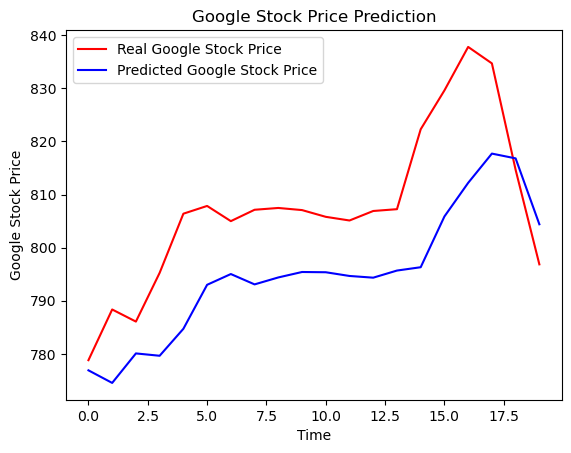

In [41]:
# Visualising the results
plt.plot(real_stock_price, color = 'red', label = 'Real Google Stock Price')
plt.plot(predicted_stock_price, color = 'blue', label = 'Predicted Google Stock Price')
plt.title('Google Stock Price Prediction')
plt.xlabel('Time')
plt.ylabel('Google Stock Price')
plt.legend()
plt.show()

In [49]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

mse = mean_squared_error(real_stock_price, predicted_stock_price)
rmse = np.sqrt(mse)
mae = mean_absolute_error(real_stock_price, predicted_stock_price)

print(f"RMSE: {rmse}")
print(f"MAE: {mae}")

RMSE: 15.03876070861121
MAE: 13.48382055664062
